# Predicting Transfer Market Value in Football using Football Manager 2024 Data
### MSc Artificial Intelligence and Data Science – Osasumwen Okunkpolor


### This notebook documents the Random Forest model used to predict football transfer market values using Football Manager 2024 data.

### Importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import shap

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load Prepared DatasetLoads the cleaned FM24 dataset with league-strength values for model training

In [2]:
# Load the cleaned dataset containing league-strength values
df = pd.read_excel("../data/fm_with_league_strength.xlsx")
# Display the dataset shape to confirm number of rows and columns
print(df.shape)

# Show the first few rows for a quick inspection
df.head()


(15832, 65)


,Name,Age,Position,Club,Nat,Height,Weight,CA,PA,Begins,...,PA_norm,potential_growth_norm,CR_norm,WR_norm,inj_pr_norm,Wage_clean,Wage_log,y,scaler,league_strength
0,Bernardo Silva,28,M/AM (RC),Man City,POR,173 cm,64 kg,178,180,2023-07-03,...,0.900,0.010,0.890,0.890,0.30,250000.0,12.429220,280000000.0,1.0,96.227
1,Ederson,29,GK,Man City,BRA,188 cm,86 kg,180,180,2021-09-01,...,0.900,0.000,0.880,0.850,0.25,180000.0,12.100718,227500000.0,1.0,96.227
2,Rúben Dias,26,D (C),Man City,POR,186 cm,83 kg,174,177,2021-08-30,...,0.885,0.015,0.870,0.850,0.20,175000.0,12.072547,225500000.0,1.0,96.227
3,Rodri,27,"D (C), DM, M (C)",Man City,ESP,191 cm,75 kg,177,177,2022-07-12,...,0.885,0.000,0.885,0.825,0.20,165000.0,12.013707,239500000.0,1.0,96.227
4,Martin Ødegaard,24,M/AM (C),Arsenal,NOR,178 cm,68 kg,173,180,2023-07-03,...,0.900,0.035,0.865,0.775,0.35,225000.0,12.323860,215500000.0,1.0,96.227


### Position Grouping and Encoding: Simplifies player positions into four role groups and creates one-hot encoded dummy variables.

In [3]:
# Extract the player’s primary position and group into broader role categories
def extract_primary_position(pos_text):
    """
    Extract the first listed position (before any commas)
    and simplify its label.
    """
    if pd.isna(pos_text):
        return "UNK"
    
     # Select the first position and convert to uppercase
    primary = pos_text.split(",")[0].strip().upper()

     # Classify the position into one of four main groups
    if "GK" in primary:
        return "GK"
    # Defenders (including wing-backs and sweepers
    elif primary.startswith("D") or "WB" in primary or "SW" in primary:
        return "DEF"
    # Midfielders including defensive mids
    elif primary.startswith("M") or "DM" in primary:
        return "MID"
    # Forwards/Attackers
    elif "AM" in primary or "ST" in primary or "FW" in primary:
        return "FWD"
    else:
        return "UNK"

# Apply the classification
df["pos_group"] = df["Position"].apply(extract_primary_position)

# Create one-hot encoded dummy variables for each position group
pos_dummies = pd.get_dummies(df["pos_group"], prefix="pos")

# Merge them back into your main DataFrame
df = pd.concat([df, pos_dummies], axis=1)

# Verify new columns and check the distribution of position groups
print([col for col in df.columns if col.startswith("pos_")])
print(df["pos_group"].value_counts())


['pos_group', 'pos_DEF', 'pos_FWD', 'pos_GK', 'pos_MID']
pos_group
DEF    7777
FWD    3599
MID    2828
GK     1628
Name: count, dtype: int64


### Feature Engineering: Creates additional features capturing performance, contract, reputation, and age dynamics to improve model accuracy and interpretability.

In [4]:
# FEATURE ENGINEERING

# Compute squared age term to model non-linear ageing effects
df["Age_sq"] = df["Age"] ** 2

# Calculate the ratio of remaining to total contract duration
df["contract_ratio"] = df["contract_years_remaining"] / (df["contract_years_total"] + 1e-6)

# Scale league strength between 0 and 1 for comparability across leagues
df["league_strength_scaled"] = df["league_strength"] / df["league_strength"].max()

# Compute contract decay to represent declining transfer leverage as contracts near expiry
df["contract_decay"] = np.exp(-df["contract_years_remaining"])

# Measure how close a player’s current ability is to their potential
df["potential_ratio"] = df["CA_norm"] / (df["PA_norm"] + 1e-6)

# Combine league strength with contract duration to represent accumulated experience
df["experience_strength"] = df["league_strength_scaled"] * df["contract_years_total"]

# Penalise players with higher injury proneness relative to ability
df["injury_penalty"] = df["inj_pr_norm"] * (200 - df["CA"])

# Log-transform wage to reduce skew and normalise by league strength for comparability
if "Wage_log" not in df.columns:
    df["Wage_log"] = np.log1p(df["Wage"].astype(float))
df["wage_normalised"] = df["Wage_log"] / (df["league_strength_scaled"] + 1e-6)

# Normalise current and world reputation to a 0–1 scale and compute the reputation gap
df["CR_norm"] = df["CR"] / 10000.0
df["WR_norm"] = df["WR"] / 10000.0
df["reputation_gap"] =  df["CR_norm"] - df["WR_norm"]


In [5]:
# ADVANCED FEATURE ENGINEERING

# Combine age and ability to represent experience-weighted performance
df["Age_CA"] = df["Age"] * df["CA_norm"]

# Measure the gap between potential and current ability to reflect development headroom
df["potential_gap"] = df["PA_norm"] - df["CA_norm"]

# Include a squared contract term to model non-linear effects of remaining years
df["contract_remaining_sq"] = df["contract_years_remaining"] ** 2

# Adjust wages relative to league competitiveness to provide economic context
df["wage_league_ratio"] = df["Wage_log"] / (df["league_strength_scaled"] + 1e-6)

# Create a league-adjusted reputation metric by combining league strength with the player's current reputation
df["club_reputation_proxy"] = df["league_strength_scaled"] * df["CR_norm"]

# Reduce effective ability for players with high injury risk
df["CA_adj"] = df["CA_norm"] * (1 - df["inj_pr_norm"])

# Model regional familiarity by interacting nationality with league strength
df["nat_league_interaction"] = df["league_strength_scaled"] * df["scaler"]

# Capture player reliability as the mean of current and world reputation scores
df["consistency_proxy"] = (df["CR_norm"] + df["WR_norm"]) / 2


In [6]:
# # Define age-based features to model player performance around their career peak
AGE_PEAK = 27

# Measure years above and below the typical peak age
df["age_over"]  = np.clip(df["Age"] - AGE_PEAK, 0, None)   # years above peak
df["age_under"] = np.clip(AGE_PEAK - df["Age"], 0, None)   # years below peak

# Include a squared term to capture the accelerating decline after peak age
df["age_over_sq"] = df["age_over"] ** 2

# Flag elite players based on high current and current reputation scores
df["elite_flag"] = ((df["CA_norm"] >= 0.93) & (df["CR_norm"] >= 0.93)).astype(int)

# Model how elite players maintain performance longer beyond their peak
df["age_over_elite"] = df["age_over"] * df["elite_flag"]

# Compute the ratio of age to ability to show how ageing relates to performance
df["age_CA_ratio"] = df["Age"] / (df["CA_norm"] * 100)   # higher = older relative to ability


# Add a balancing term showing how elite players’ decline is moderated with age
df["elite_age_balance"] = df["elite_flag"] * (1 / (1 + df["age_over"]))

### Train/Test Split: Separates players with known market values for model training and those marked “Not for Sale” for testing.


In [7]:
# TRAIN / TEST SPLIT
# Select players with known transfer values for model training
train_df = df[df["fm_value_mid"].notna()].copy()   

# Select players without market values for prediction
test_df  = df[df["fm_value_mid"].isna()].copy()    

print("Training data:", train_df.shape)
print("Not-for-sale test data:", test_df.shape)

Training data: (13412, 94)
Not-for-sale test data: (2420, 94)


### Define Features and Target: Selects key predictive variables and applies a log transformation to the target to reduce skewness before training.


In [8]:
# Define model features and prepare the target variable
# Specify all predictive features including ability, contract, wage, reputation, and engineered metrics
features = [
    "CA_norm", "PA_norm", "potential_growth_norm",
    "contract_ratio", "contract_decay",
    "league_strength_scaled", "experience_strength",
    "Wage_log", "wage_normalised",
    "inj_pr_norm", "injury_penalty", "uefa_points",
    "CR_norm", "WR_norm", "reputation_gap",
    "pos_DEF", "pos_FWD", "pos_GK", "pos_MID",
    "Age_CA", "potential_gap", "contract_remaining_sq",
    "wage_league_ratio", "club_reputation_proxy",
    "CA_adj", "nat_league_interaction", "consistency_proxy",
    "age_under", "age_over", "age_over_sq","elite_flag",
    "age_over_elite","age_CA_ratio", "elite_age_balance"


]


# Apply log transformation to the target to reduce skewness and stabilise
train_df["fm_value_mid_log"] = np.log1p(train_df["fm_value_mid"])
target = "fm_value_mid_log"

# Separate predictors (X) and target variable (y)
X = train_df[features]
y = train_df[target]

# Split the dataset into training and validation sets for model evaluation
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

Train shape: (10729, 34)
Validation shape: (2683, 34)


### Random Forest Model Hyperparameter Tuning and Validation: Trains a Random Forest Regressor with manually tuned parameters to predict player market values, then evaluates its performance using MAE, RMSE, and R² metrics on the validation set.


In [9]:
# Initialize a Random Forest Regressor with manually tuned hyperparameters
# The model uses 400 trees, limits depth to 15, and controls overfitting with min_samples_leaf and max_features
best_rf_model = RandomForestRegressor(
    n_estimators=400,   
    max_depth=15,       
    min_samples_leaf=5, 
    max_features=0.6,   
    bootstrap=True,      
    random_state=42,    
    n_jobs=-1           
)


# Train the Random Forest model on the training dataset
best_rf_model.fit(X_train, y_train)

# Generate predictions on the validation set (still in log scale)
y_pred_valid_log = best_rf_model.predict(X_valid)

# Convert predictions and actual values back from log scale to original (£) units
y_pred_valid = np.expm1(y_pred_valid_log)
y_true_valid = np.expm1(y_valid)

### Random Forest Predictions and Realism Adjustments: Generates predicted market values for test players, calibrated against validation results and adjusted for realism using age-based depreciation, youth bonuses, and positional multipliers.


In [10]:
# Select feature columns for prediction
X_test = test_df[features]

# Predict player values (in log scale) using the trained model
y_pred_test_log = best_rf_model.predict(X_test)

# Convert predictions back to the original scale
test_df["predicted_value_raw"] = np.expm1(y_pred_test_log)  # unlogged £ values

# Apply age-based depreciation adjustment for realism
AGE_PEAK = 27
DECAY_RATE = 0.035  # 3.5% per year after peak
test_df["predicted_value"] = (
    test_df["predicted_value_raw"] *
    np.exp(-DECAY_RATE * (test_df["Age"] - AGE_PEAK).clip(lower=0))
)

# Apply youth bonus for players under age 21 to reflect development potential
YOUTH_BONUS_RATE = 0.015
test_df.loc[test_df["Age"] < 21, "predicted_value"] *= np.exp(
    YOUTH_BONUS_RATE * (21 - test_df["Age"])
)



In [11]:
# Convert both validation targets and predictions back from log scale (£ units)
y_true_valid = np.expm1(y_valid)
y_pred_valid = np.expm1(best_rf_model.predict(X_valid))


# Calculate a calibration factor by comparing the mean of actual vs predicted values
# This helps align model outputs with realistic market value scales
scale_factor = np.mean(y_true_valid) / np.mean(y_pred_valid)
print(f"Calibration factor for Random Forest: {scale_factor:.3f}")

# Apply the calibration factor to predictions for test players
# This ensures that the predicted market values are adjusted proportionally
test_df["predicted_value_adj_calibrated"] = (
    np.expm1(best_rf_model.predict(X_test)) * scale_factor
)

Calibration factor for Random Forest: 1.199


In [12]:
# Apply positional adjustment factors to reflect market differences by role
POSITION_MULTIPLIER = {
    "GK": 0.55,   
    "DEF": 0.75,  
    "MID": 1.00,  
    "FWD": 1.00   
}

# Adjust predicted market values using position-specific multipliers
test_df["predicted_value_adj"] = test_df.apply(
    lambda r: r["predicted_value"] * POSITION_MULTIPLIER.get(r["pos_group"], 1.0),
    axis=1
)


In [13]:
print("\nPredicted values for Not-for-Sale players (sample):")

# Format adjusted predicted values in £ for easier readability
test_df["predicted_value_adj_display"] = test_df["predicted_value_adj"].apply(lambda x: f"£{x:,.0f}")

# Display a random sample of 10 players with key details and predicted values
display(
display(
    test_df[[
        "Name", "Age", "Club", "Division", "country",
        "predicted_value", "predicted_value_adj_display"
    ]].sample(10, random_state=42)
)
)


Predicted values for Not-for-Sale players (sample):


,Name,Age,Club,Division,country,predicted_value,predicted_value_adj_display
13822,Jordan Longhi,18,Brianza,Italian Serie A,Italy,247923.635868,"£247,924"
13611,Noah Adekoya,18,Burnley,English Premier Division,England,15108.845147,"£11,332"
15086,Dermot Mee,20,Man UFC,English Premier Division,England,50425.352183,"£27,734"
14536,Michele Carboni,18,Cagliari,Italian Serie A,Italy,94358.779063,"£70,769"
14767,Ethan Brierley,19,Brentford,English Premier Division,England,333320.603960,"£249,990"
14303,Andrea Coati,18,Atalanta,Italian Serie A,Italy,68501.619488,"£68,502"
13666,Paris Lock,18,AFC Wimbledon,Sky Bet League Two,England,36152.572810,"£36,153"
15517,Nicolò Bianchi,31,Padova,Italian Serie C/A,Italy,143623.733036,"£107,718"
14957,Côme Bianay,18,Torino,Italian Serie A,Italy,29622.839114,"£22,217"
15131,Dimitris Keramitsis,19,AS Roma,Italian Serie A,Italy,209517.535824,"£157,138"


None

### Display Players with Release Clauses: Formats and displays predicted market values alongside official release clauses, sorted by highest clause values.


In [14]:
# Display top players who have active release clauses alongside predicted values
# Define helper function to format each player's predicted value with their release clause
def format_predicted_with_clause(row):
    """Format predicted value alongside release clause."""
    val = row["predicted_value"]
    clause = row["release_all"]
    pred_str = f"£{val:,.0f}"
    if pd.notna(clause) and clause > 0:
        clause_str = f" (Release: £{clause/1e6:.0f}M)"
        return pred_str + clause_str
    else:
        return pred_str

# Apply the formatting function to each player record
test_df["predicted_display"] = test_df.apply(format_predicted_with_clause, axis=1)

# Filter dataset to include only players with defined release clauses
has_clause = test_df.loc[test_df["release_all"].notna() & (test_df["release_all"] > 0)].copy()
print(f"Players with release clauses: {has_clause.shape[0]}")

# Add formatted columns for presentation (release clause and predicted market value)
has_clause.loc[:, "Release Clause (£M)"] = has_clause["release_all"].apply(lambda x: f"£{x/1e6:.0f}M")
has_clause.loc[:, "Predicted Market Value (£M)"] = has_clause["predicted_value_adj"].apply(lambda x: f"£{x/1e6:.1f}M")

# Sort the dataset by release clause value (highest first)
has_clause_sorted = has_clause.sort_values(by="release_all", ascending=False)

# Display the top 10 players with release clauses in a formatted table
display(
    has_clause_sorted[[
        "Name", "Club", "Division", "country",
        "Release Clause (£M)", "Predicted Market Value (£M)"
    ]].head(10)
)


Players with release clauses: 120


,Name,Club,Division,country,Release Clause (£M),Predicted Market Value (£M)
15522,David Alaba,R. Madrid,Spanish First Division,Spain,£729M,£43.0M
15611,Thibaut Courtois,R. Madrid,Spanish First Division,Spain,£600M,£62.1M
15809,Robert Lewandowski,Barcelona,Spanish First Division,Spain,£429M,£28.5M
15544,Marc-André ter Stegen,Barcelona,Spanish First Division,Spain,£429M,£49.6M
15713,Antoine Griezmann,A. Madrid,Spanish First Division,Spain,£429M,£33.6M
15749,İlkay Gündoğan,Barcelona,Spanish First Division,Spain,£343M,£20.5M
15577,William Carvalho,Real Hispalis,Spanish First Division,Spain,£103M,£14.0M
15775,Gerard Moreno,Villarreal,Spanish First Division,Spain,£86M,£26.9M
15493,Iago Aspas,Vigo,Spanish First Division,Spain,£43M,£4.9M
15747,Marcos Acuña,Sevilla,Spanish First Division,Spain,£35M,£8.5M


### Top 10 Players by Predicted Market Value: Displays the ten highest-valued players based on Random Forest predictions, formatted for clear presentation.


In [15]:
# Display the top 10 players ranked by predicted market value from the Random model

# Sort the dataset in descending order based on adjusted predicted market values

top_predicted = (
    test_df.sort_values(by="predicted_value_adj", ascending=False)
    .loc[:, ["Name", "Club", "Division", "country", "predicted_value_adj"]]
    .head(10)
    .copy()
)

# Format predicted values in millions of pounds for clearer presentation
top_predicted["Predicted Market Value (£M)"] = top_predicted["predicted_value_adj"].apply(lambda x: f"£{x/1e6:.1f}M")

# Print title for readability and display the formatted top 10 table
print("Top 10 Players by Predicted Market Value")
display(
    top_predicted[["Name", "Club", "Division", "country", "Predicted Market Value (£M)"]]
)


Top 10 Players by Predicted Market Value


,Name,Club,Division,country,Predicted Market Value (£M)
15722,Erling Haaland,Man City,English Premier Division,England,£185.7M
15628,Mohamed Salah,Liverpool,English Premier Division,England,£119.6M
15507,Virgil van Dijk,Liverpool,English Premier Division,England,£89.8M
15626,Kevin De Bruyne,Man City,English Premier Division,England,£83.2M
15611,Thibaut Courtois,R. Madrid,Spanish First Division,Spain,£62.1M
15544,Marc-André ter Stegen,Barcelona,Spanish First Division,Spain,£49.6M
15522,David Alaba,R. Madrid,Spanish First Division,Spain,£43.0M
15582,Casemiro,Man UFC,English Premier Division,England,£37.0M
15713,Antoine Griezmann,A. Madrid,Spanish First Division,Spain,£33.6M
15809,Robert Lewandowski,Barcelona,Spanish First Division,Spain,£28.5M


### Save Predictions: Exports the final adjusted market value predictions for test players to an Excel file.

In [16]:
# SAVING PREDICTIONS
# Define output filename for storing adjusted predictions
output_file = "../outputs/predictions_random_forest.xlsx"

# Select key columns to include in the exported dataset
cols_to_export = [
    "Name", "Club", "Division", "country",
    "Age", "predicted_value", "predicted_value_adj"
]
test_df[cols_to_export].to_excel(output_file, index=False)
print(f"Exported adjusted Not-for-Sale predictions to: {output_file}")

Exported adjusted Not-for-Sale predictions to: predicted_not_for_sale_players_adjusted(rabndom forest).xlsx


### Model Evaluation: Evaluates the model on the validation set using MAE, RMSE, R², and MAPE to assess predictive accuracy and fit.

In [17]:
# Convert predicted and actual values back from the logarithmic scale
y_true = np.expm1(y_valid)  # convert back from log
y_pred = np.expm1(best_rf_model.predict(X_valid))

# Compute key regression performance metrics
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Display model performance results in readable format
print(f"Validation MAE: £{mae:,.0f}")
print(f"Validation RMSE: £{rmse:,.0f}")
print(f"R²: {r2:.3f}")
print(f"MAPE: {mape:.2f}%")


Validation MAE: £1,305,557
Validation RMSE: £5,885,936
R²: 0.848
MAPE: 75.26%


### Explainability Analysis (SHAP): Uses SHAP values to interpret the Random Forest model, showing the most influential features affecting predicted market values.


In [18]:
# Perform explainability analysis using SHAP to interpret feature importance in the Random Forest model

# Create a SHAP TreeExplainer instance for the trained model
explainer = shap.TreeExplainer(best_rf_model)

# Generate SHAP values to measure each feature’s contribution to predictions
shap_values = explainer.shap_values(X_valid)

# Convert SHAP values into a DataFrame for easier inspection and analysis
shap_df = pd.DataFrame(shap_values, columns=X_valid.columns)


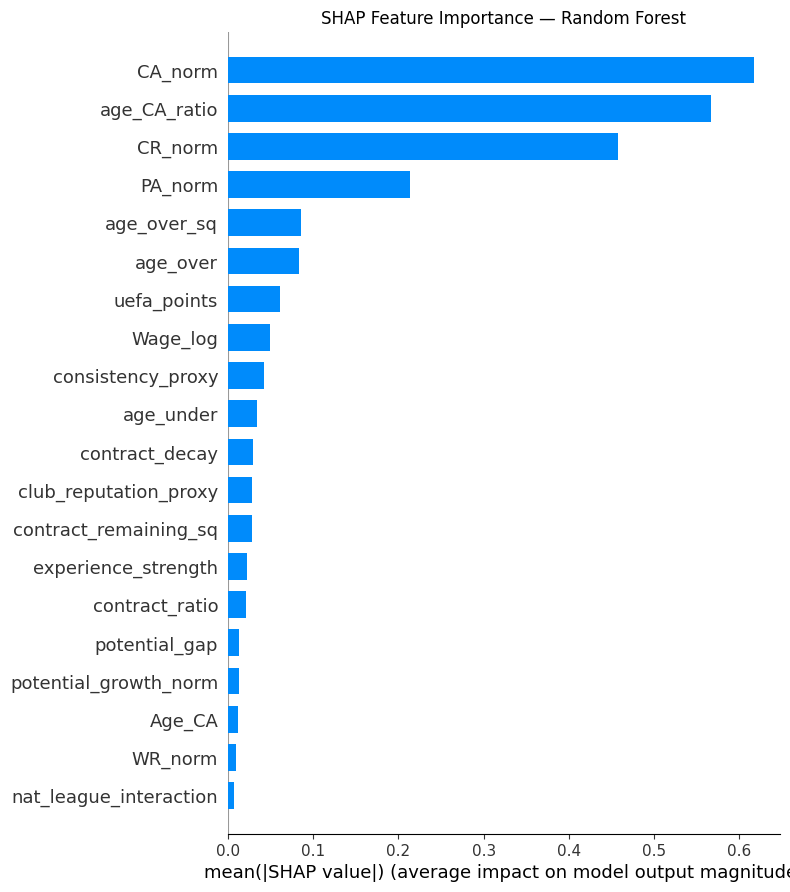

In [19]:
# Plot a summary bar chart showing average feature importance across the validation set
shap.summary_plot(shap_values, X_valid, plot_type="bar", show=False)
plt.title("SHAP Feature Importance — Random Forest")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Automated Player Explanation (SHAP): Defines a function to generate SHAP force plots and feature contribution tables for individual players, illustrating key factors influencing their predicted market values.


--- Player 1: Thibaut Courtois (R. Madrid) ---


,Feature,Value,SHAP_Impact
0,CA_norm,0.905,2.054081
1,CR_norm,0.905,1.791514
2,age_CA_ratio,0.342541,1.107113
3,PA_norm,0.905,0.861596
4,consistency_proxy,0.88,0.192803
5,Wage_log,12.42922,0.155527
6,club_reputation_proxy,0.748419,0.081281
7,experience_strength,4.027929,0.023524
8,contract_decay,0.049889,0.023373
9,WR_norm,0.855,0.021931


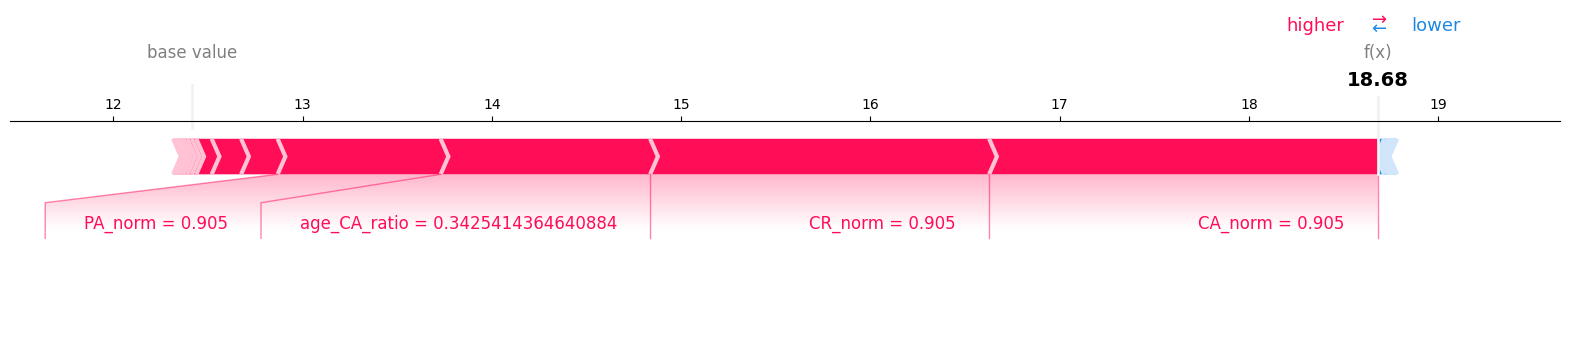

Displayed SHAP force plot for Thibaut Courtois.


--- Player 1: Erling Haaland (Man City) ---


,Feature,Value,SHAP_Impact
0,CA_norm,0.94,2.046330
1,CR_norm,0.94,1.729525
2,age_CA_ratio,0.234043,1.240252
3,PA_norm,0.975,0.876248
4,consistency_proxy,0.92,0.176795
5,Wage_log,12.765691,0.160461
6,club_reputation_proxy,0.94,0.113124
7,uefa_points,96.227,0.067230
8,age_over_sq,0,0.052159
9,age_over,0,0.047567


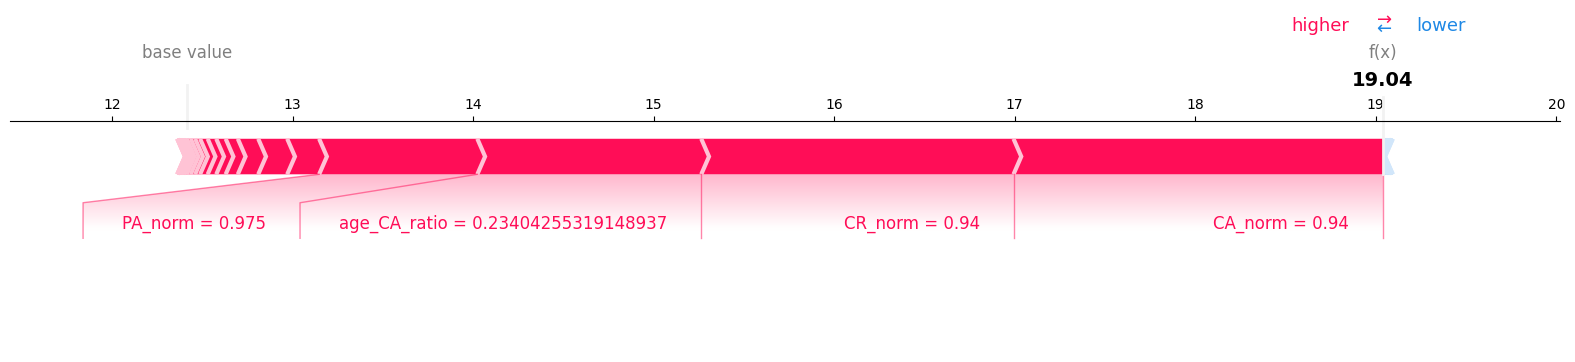

Displayed SHAP force plot for Erling Haaland.



In [20]:
# Define a reusable function to generate SHAP-based explanations for any individual player
def explain_player(player_name, df, model, features, explainer):
    """
    Generate a SHAP force plot and feature contribution table for any player.
    Works for Random Forest, XGBoost, or other tree-based models.
    """
    import shap
    import pandas as pd

    # Select feature columns used during model training
    X_test = df[features]
    shap_values = explainer.shap_values(X_test)

    # Locate player(s) whose name matches the provided query
    matches = df[df["Name"].str.contains(player_name, case=False, na=False)]
    if matches.empty:
        print(f"No player found matching '{player_name}'. Try another name.")
        return

    # Generate explanation for each matching player
    for i, (idx, row) in enumerate(matches.iterrows(), start=1):
        player_position = df.index.get_loc(idx)
        player_features = X_test.iloc[[player_position]]
        player_shap = shap_values[player_position]

        print(f"\n--- Player {i}: {row['Name']} ({row['Club']}) ---")

       # Create a ranked table of top features influencing this player's valuation
        contrib_df = (
            pd.DataFrame({
                "Feature": player_features.columns,
                "Value": player_features.values[0],
                "SHAP_Impact": player_shap
            })
            .sort_values("SHAP_Impact", ascending=False)
            .reset_index(drop=True)
        )

        display(contrib_df.head(10))  # show top 10 influential features

         # Generate a SHAP force plot to visualise feature effects on prediction
        shap.force_plot(
            explainer.expected_value,
            player_shap,
            player_features,
            matplotlib=True
        )

        print(f"Displayed SHAP force plot for {row['Name']}.\n")

# Generate interpretability outputs for selected players
explainer = shap.TreeExplainer(best_rf_model)
explain_player("Thibaut Courtois", test_df, best_rf_model, features, explainer)
explain_player("Erling Haaland", test_df, best_rf_model, features, explainer)



--- Player 1: Kevin De Bruyne (Man City) ---


,Feature,Value,SHAP_Impact
0,CA_norm,0.95,1.975804
1,CR_norm,0.95,1.702783
2,age_CA_ratio,0.336842,1.208517
3,PA_norm,0.95,0.815475
4,consistency_proxy,0.95,0.172888
5,Wage_log,12.765691,0.157527
6,club_reputation_proxy,0.95,0.110925
7,uefa_points,96.227,0.068363
8,experience_strength,4.147844,0.030913
9,WR_norm,0.95,0.018190


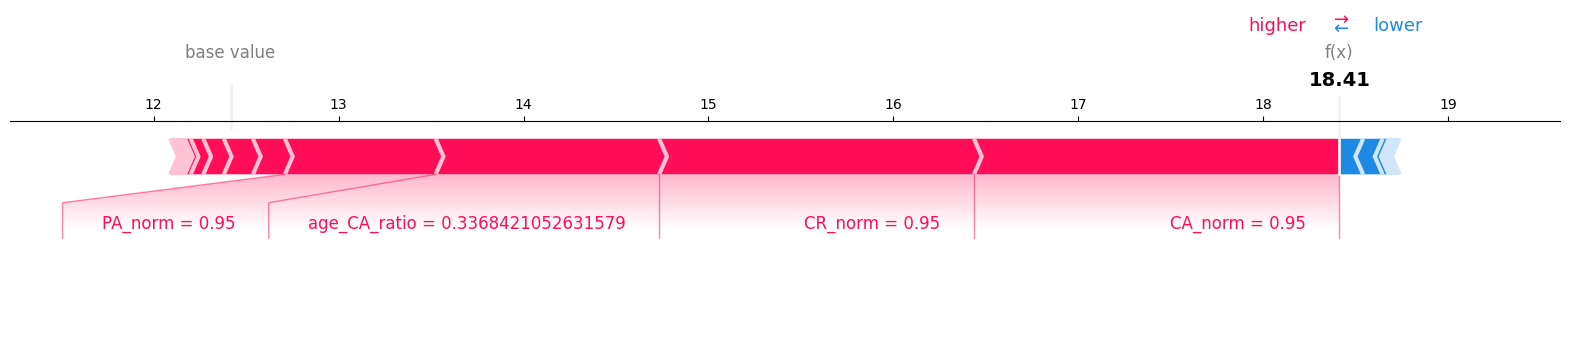

Displayed SHAP force plot for Kevin De Bruyne.



In [21]:
explain_player("Kevin De Bruyne", test_df, best_rf_model, features, explainer)